# Notebook 01 - Data Audit and Exploratory Data Analysis

**Project:** Bank Customer Churn Prediction (Devixo Solutions AI/ML Internship, Task 04)

**Goal of this notebook:** look at the raw data *without changing it*, record every data problem we find (or do not find),
and understand which customer details are linked to churn. Every decision made here is carried into notebook 02.

**Rule:** the raw file `data/raw/Bank Customer Churn Prediction.csv` is never edited. All work is done on copies in memory.

In [1]:
import os, sys, warnings
from pathlib import Path

# Work from the project root whether the notebook is opened from the root or from notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
print("Project root:", ROOT)

Project root: /home/claude/bank-churn-app


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_utils import load_raw, validate, iqr_outlier_counts, TARGET, ID_COL

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")


def save(name):
    """Save the current figure as a PNG (used later in the report) and show it here."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150)
    plt.show()
    plt.close()

## 1. Load the data and run quality checks

We check shape, column types, missing values (including blank text), duplicates (also ignoring the ID, because a unique ID makes
duplicate customers look different), and whether `customer_id` is unique.

In [3]:
df = load_raw()
display(df.head())
print("Column types:")
print(df.dtypes)
print()
for key, value in validate(df).items():
    print(f"{key}: {value}")

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Column types:
customer_id           int64
credit_score          int64
country                 str
gender                  str
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object

shape: (10000, 12)
missing_total: 0
blank_strings: 0
full_duplicates: 0
duplicates_ignoring_id: 0
id_is_unique: True
target_values: [0, 1]
missing_columns: []


**What this tells us:** the checks above are the evidence for the cleaning decisions. If a check finds nothing, we write that down
honestly instead of inventing a problem. `customer_id` is an identifier, so it will not be used as a model input.

## 2. Target distribution

The target `churn` is 1 when the customer left the bank. How balanced it is decides which metrics we can trust later.

churn
0    7963
1    2037
Name: count, dtype: int64

churn
0    0.796
1    0.204
Name: count, dtype: float64

Accuracy of a model that always predicts 'stays': 0.796


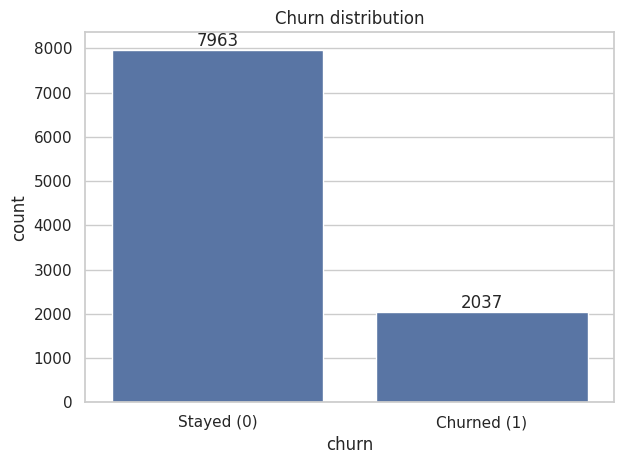

In [4]:
counts = df[TARGET].value_counts().sort_index()
print(counts)
print()
print((counts / len(df)).round(3))
print()
print("Accuracy of a model that always predicts 'stays':", round(counts[0] / len(df), 3))

ax = sns.countplot(data=df, x=TARGET)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
ax.set_title("Churn distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
save("01_churn_distribution.png")

**Decision:** the classes are imbalanced, so *accuracy alone would be misleading*. A model that never predicts churn would still look
accurate. We will judge models with ROC-AUC, recall and F1 as well, and split the data with stratification so train and test keep the
same churn rate.

## 3. Outlier detection

The 1.5 x IQR rule flags values far outside the middle 50% of the data. It only *detects*. Whether to remove a flagged value is a
separate decision that depends on whether the value is plausible.

,column,lower_bound,upper_bound,n_outliers,pct,min,max
0,credit_score,383.00000,919.00000,15,0.15,350.00,850.00
1,age,14.00000,62.00000,359,3.59,18.00,92.00
2,tenure,-3.00000,13.00000,0,0.00,0.00,10.00
3,balance,-191466.36000,319110.60000,0,0.00,0.00,250898.09
4,estimated_salary,-96577.09625,296967.45375,0,0.00,11.58,199992.48


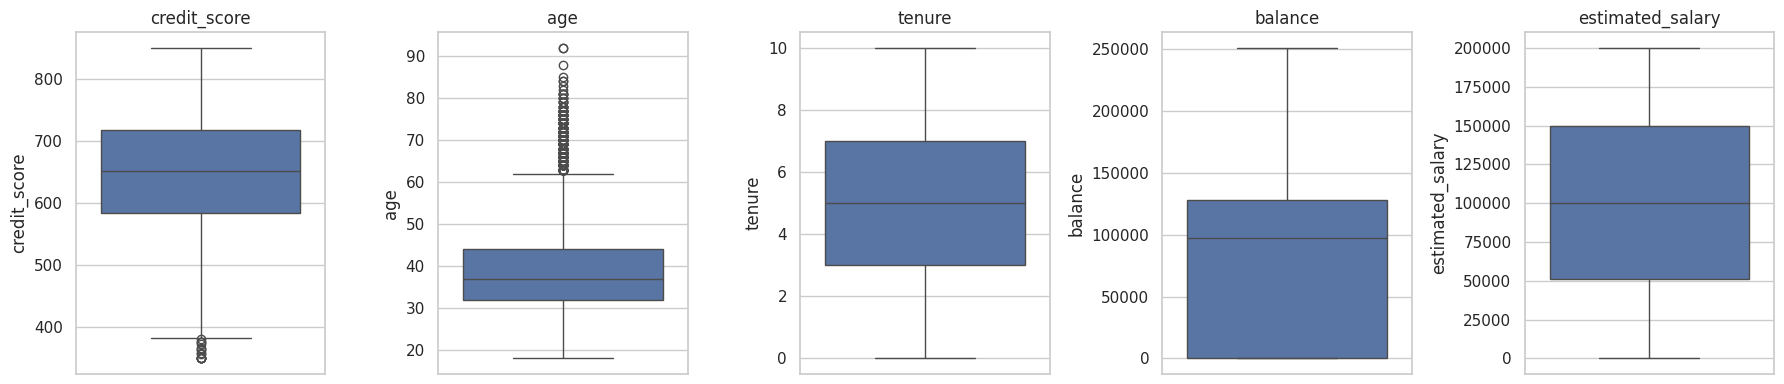

In [5]:
display(iqr_outlier_counts(df))

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, ["credit_score", "age", "tenure", "balance", "estimated_salary"]):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
save("02_boxplots_outliers.png")

In [6]:
# Investigate the flagged values: are they plausible customers?
print(df["age"].describe())
old = df[df["age"] >= 70]
print()
print("Customers aged 70+:", len(old), "| their churn rate:", round(old[TARGET].mean(), 3),
      "| overall churn rate:", round(df[TARGET].mean(), 3))
print("Credit scores below 400:", (df["credit_score"] < 400).sum(), "| lowest score:", df["credit_score"].min())

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: age, dtype: float64

Customers aged 70+: 151 | their churn rate: 0.099 | overall churn rate: 0.204
Credit scores below 400: 19 | lowest score: 350


**Decision: keep the outliers.** Ages up to the low 90s and credit scores from 350 are plausible values for real bank customers, not
data-entry errors. Older customers also have a *different* churn rate, so deleting them would remove real information. Tree models are
not sensitive to such values, and the other models will use standardised inputs. This is a judgement based on the evidence and it is
written in `docs/decisions.md`, so it can be reversed.

## 4. Churn rate by group

The churn rate of a group is simply the mean of the 0/1 target in that group. The red dashed line is the overall churn rate, and
`n` is the group size (small groups give less reliable rates). All panels share the same y-axis so the bars can be compared.

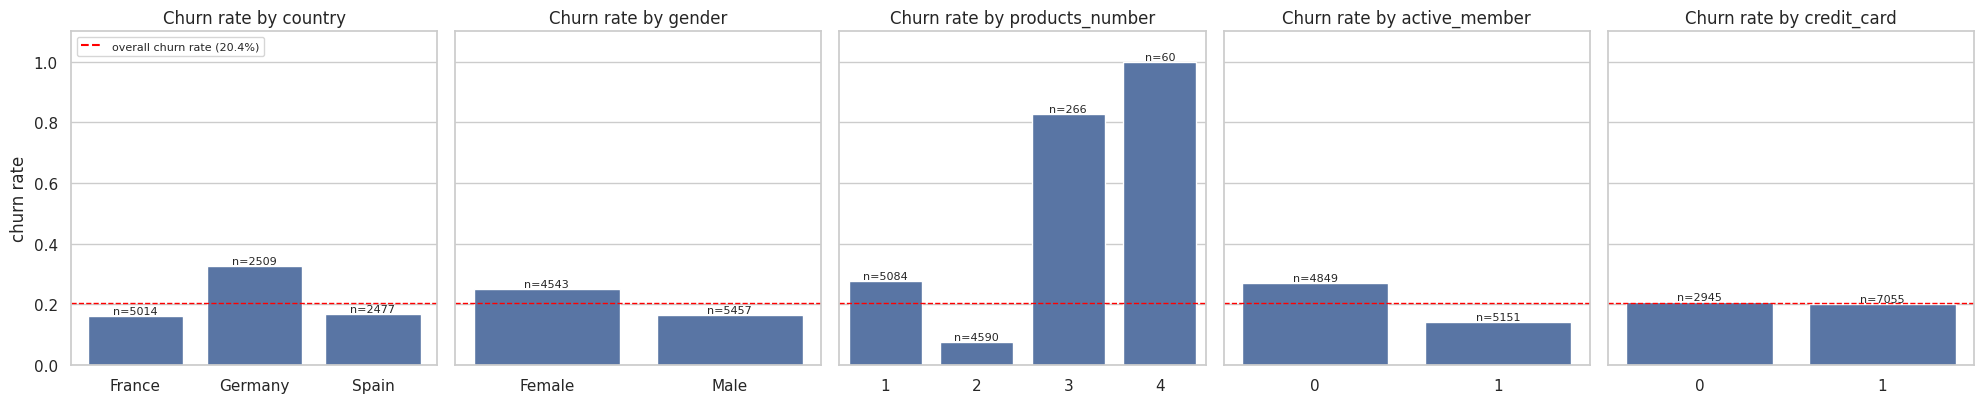

,mean,count
country,,
France,0.162,5014
Germany,0.324,2509
Spain,0.167,2477


,mean,count
gender,,
Female,0.251,4543
Male,0.165,5457


,mean,count
products_number,,
1,0.277,5084
2,0.076,4590
3,0.827,266
4,1.000,60


,mean,count
active_member,,
0,0.269,4849
1,0.143,5151


,mean,count
credit_card,,
0,0.208,2945
1,0.202,7055


In [7]:
cat_cols = ["country", "gender", "products_number", "active_member", "credit_card"]
overall = df[TARGET].mean()

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2), sharey=True)
for ax, c in zip(axes, cat_cols):
    g = df.groupby(c)[TARGET].agg(["mean", "count"]).reset_index()
    sns.barplot(x=g[c].astype(str), y=g["mean"], ax=ax, color="#4c72b0")
    ax.axhline(overall, color="red", ls="--", lw=1)
    for i, r in g.iterrows():
        ax.annotate(f"n={int(r['count'])}", (i, r["mean"]), ha="center", va="bottom", fontsize=8)
    ax.set_title(f"Churn rate by {c}")
    ax.set_xlabel("")
    ax.set_ylabel("churn rate" if c == cat_cols[0] else "")
    ax.set_ylim(0, 1.1)
axes[0].plot([], [], color="red", ls="--", label=f"overall churn rate ({overall:.1%})")
axes[0].legend(loc="upper left", fontsize=8)
save("03_churn_rate_by_category.png")

for c in cat_cols:
    display(df.groupby(c)[TARGET].agg(["mean", "count"]).round(3))

**What we learn:** some groups churn much more than the overall rate (look at country, gender, activity and number of products) and
`credit_card` makes almost no difference. The groups with 3 or 4 products are small, so their very high rates are less reliable.
These are *associations*, not proof of cause.

## 5. Numeric features and churn

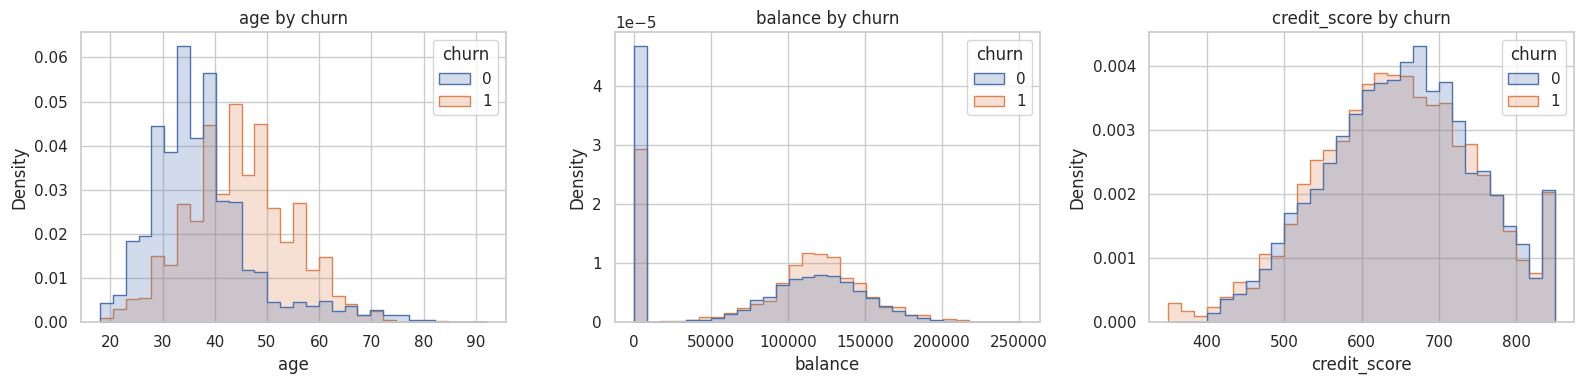

,mean,count
age,,
"(17, 30]",0.075,1968
"(30, 40]",0.121,4451
"(40, 50]",0.340,2320
"(50, 60]",0.562,797
"(60, 100]",0.248,464


Zero-balance customers: 3617 (36.2%) | churn rate zero vs non-zero balance: 0.138 vs 0.241


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["age", "balance", "credit_score"]):
    sns.histplot(data=df, x=c, hue=TARGET, bins=30, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(f"{c} by churn")
save("04_numeric_by_churn.png")

age_bands = pd.cut(df["age"], [17, 30, 40, 50, 60, 100])
display(df.groupby(age_bands, observed=True)[TARGET].agg(["mean", "count"]).round(3))

zero = df["balance"] == 0
print("Zero-balance customers:", int(zero.sum()), f"({zero.mean():.1%})",
      "| churn rate zero vs non-zero balance:",
      round(df.loc[zero, TARGET].mean(), 3), "vs", round(df.loc[~zero, TARGET].mean(), 3))

**What we learn:** churn does **not** rise steadily with age (it is highest in the middle-to-older bands and lower again for the
oldest customers), so a single straight-line effect of age would miss this. A large group of customers has a balance of exactly 0;
that is a valid group, not missing data. Both observations motivate feature engineering in notebook 02.

## 6. Correlation

Correlation measures *linear* association between numeric columns. It does not show cause, and a weak value does not prove a
feature is useless.

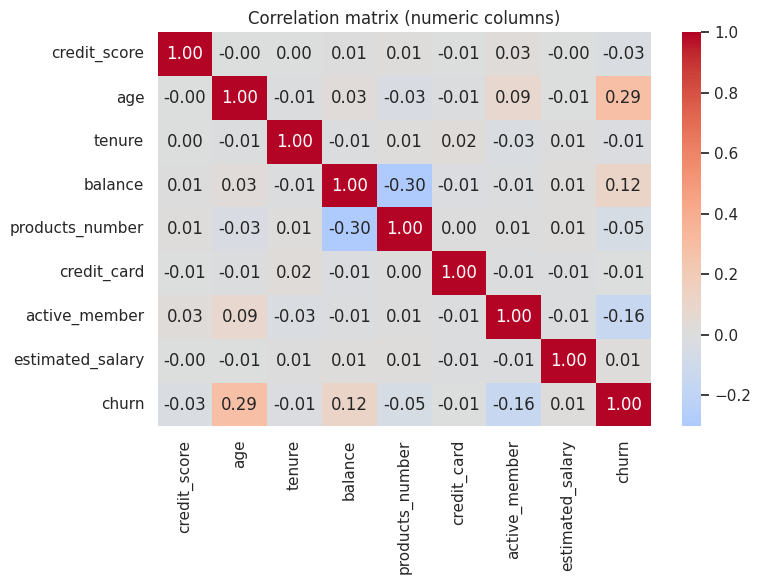

age                 0.285
active_member      -0.156
balance             0.119
products_number    -0.048
credit_score       -0.027
tenure             -0.014
estimated_salary    0.012
credit_card        -0.007
Name: churn, dtype: float64


In [9]:
num = df.drop(columns=[ID_COL]).select_dtypes("number")
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric columns)")
save("05_correlation_heatmap.png")
print(num.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

## 7. Summary of decisions carried to notebook 02

| Finding | Decision |
|---|---|
| No missing values, no blanks, no duplicates | Still implement imputation and duplicate removal (tested), but report "none found" |
| `customer_id` is a unique identifier | Drop it; never a model input |
| Classes are imbalanced | Judge models by ROC-AUC, recall and F1; stratified split |
| IQR outliers are plausible values | Keep them |
| Churn is not linear in age; zero balance is a real group; many products behave differently | Engineer `age_group`, `balance_zero`, `many_products`, `balance_to_salary` and test them |